In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [19]:
file_path = "../data/Afficionado Coffee Roasters.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [20]:
df.shape

(149116, 11)

In [21]:
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [22]:
df.columns.tolist()

['transaction_id',
 'year',
 'transaction_time',
 'transaction_qty',
 'store_id',
 'store_location',
 'product_id',
 'unit_price',
 'product_category',
 'product_type',
 'product_detail']

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  str    
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  str    
 9   product_type      149116 non-null  str    
 10  product_detail    149116 non-null  str    
dtypes: float64(1), int64(5), object(1), str(4)
memory usage: 19.8+ MB


In [24]:
df.isnull().sum()

transaction_id      0
year                0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

In [25]:
df.isnull().sum().sum()

np.int64(0)

In [26]:
df["transaction_id"].duplicated().sum()

np.int64(0)

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
print("Minimum quantity:", df["transaction_qty"].min())
print("Maximum quantity:", df["transaction_qty"].max())
print("Invalid quantities:", (df["transaction_qty"] <= 0).sum())

Minimum quantity: 1
Maximum quantity: 8
Invalid quantities: 0


In [29]:
print("Minimum price:", df["unit_price"].min())
print("Maximum price:", df["unit_price"].max())
print("Invalid prices:", (df["unit_price"] <= 0).sum())

Minimum price: 0.8
Maximum price: 45.0
Invalid prices: 0


In [30]:
df["year"].value_counts().sort_index()

year
2025    149116
Name: count, dtype: int64

In [31]:
df["store_location"].value_counts()

store_location
Hell's Kitchen     50735
Astoria            50599
Lower Manhattan    47782
Name: count, dtype: int64

In [32]:
print(df["transaction_time"].head(10))
print(df["transaction_time"].dtype)

0    07:06:11
1    07:08:56
2    07:14:04
3    07:20:24
4    07:22:41
5    07:22:41
6    07:25:49
7    07:33:34
8    07:39:13
9    07:39:34
Name: transaction_time, dtype: object
object


In [33]:
df["transaction_time"].isnull().sum()

np.int64(0)

In [15]:
# Convert transaction_time to datetime
df["transaction_time"] = pd.to_datetime(df["transaction_time"])

# Extract hour
df["hour"] = df["transaction_time"].dt.hour

# Calculate revenue
df["revenue"] = df["transaction_qty"] * df["unit_price"]

# Check new columns
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,hour,revenue
0,1,2025,1900-01-01 07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,7,6.0
1,2,2025,1900-01-01 07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,7,6.2
2,3,2025,1900-01-01 07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,7,9.0
3,4,2025,1900-01-01 07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,7,2.0
4,5,2025,1900-01-01 07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,7,6.2


In [ ]:
# Extract hour directly from time object
df["hour"] = df["transaction_time"].apply(lambda x: x.hour)

# Calculate revenue
df["revenue"] = df["transaction_qty"] * df["unit_price"]

# Check result
df.head()

In [ ]:
total_revenue = df["revenue"].sum()
total_quantity = df["transaction_qty"].sum()
total_transactions = df["transaction_id"].nunique()

print("Total Revenue:", total_revenue)
print("Total Quantity Sold:", total_quantity)
print("Total Transactions:", total_transactions)

In [ ]:
store_sales = df.groupby("store_location")["revenue"].sum().sort_values(ascending=False)

store_sales

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
store_sales.plot(kind="bar", figsize=(8,5))

plt.title("Revenue by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Revenue")

plt.show()

In [ ]:
hour_sales = df.groupby("hour")["revenue"].sum()

hour_sales

In [ ]:
hour_sales.plot(kind="line", marker="o", figsize=(10,5))

plt.title("Hourly Revenue Trend")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")

plt.grid()
plt.show()

In [ ]:
peak_hour = hour_sales.idxmax()
peak_revenue = hour_sales.max()

print("Peak Sales Hour:", peak_hour)
print("Revenue:", peak_revenue)

In [ ]:
category_sales = df.groupby("product_category")["revenue"].sum().sort_values(ascending=False)

category_sales

In [ ]:
category_sales.plot(kind="bar", figsize=(8,5))

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.show()

In [ ]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

daily_sales = df.groupby("transaction_date")["revenue"].sum()

daily_sales.plot(
    kind="line",
    figsize=(12,5),
    title="Daily Revenue Trend"
)

plt.xlabel("Date")
plt.ylabel("Revenue")
plt.show()

In [ ]:
df.columns

In [ ]:
# Peak and lowest sales hours

peak_hour = hour_sales.idxmax()
peak_revenue = hour_sales.max()

low_hour = hour_sales.idxmin()
low_revenue = hour_sales.min()

print("Peak Sales Hour:", peak_hour)
print("Peak Revenue:", peak_revenue)

print("Lowest Sales Hour:", low_hour)
print("Lowest Revenue:", low_revenue)

In [ ]:
product_sales = df.groupby("product_type")["revenue"].sum().sort_values(ascending=False)

product_sales.head(10)

In [ ]:
product_sales.head(10).plot(
    kind="bar",
    figsize=(10,5),
    title="Top 10 Products by Revenue"
)

plt.xlabel("Product Type")
plt.ylabel("Revenue")
plt.show()

In [ ]:
store_transactions = df.groupby("store_location")["transaction_id"].count()

store_transactions

In [ ]:
store_transactions.plot(
    kind="bar",
    figsize=(8,5),
    title="Transactions by Store Location"
)

plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
year_sales = df.groupby("year")["revenue"].sum()

year_sales

In [ ]:
year_sales.plot(
    kind="line",
    marker="o",
    title="Sales Trend by Year"
)

plt.xlabel("Year")
plt.ylabel("Revenue")
plt.show()

In [ ]:
hour_sales = df.groupby("hour")["transaction_qty"].sum()

hour_sales

In [ ]:
hour_sales.plot(
    kind="bar",
    figsize=(10,5),
    title="Transactions by Hour"
)

plt.xlabel("Hour")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
category_sales = (
    df.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

In [ ]:
category_sales.plot(
    kind="bar",
    figsize=(8,5),
    title="Revenue by Product Category"
)

plt.xlabel("Category")
plt.ylabel("Revenue")
plt.show()

In [ ]:
df["transaction_time"].head()

In [ ]:
df["transaction_time"] = pd.to_datetime(df["transaction_time"])

df["day"] = df["transaction_time"].dt.day_name()

day_sales = df.groupby("day")["revenue"].sum().sort_values(ascending=False)

day_sales

In [ ]:
hour_revenue = df.groupby("hour")["revenue"].sum()

hour_revenue

In [ ]:
hour_revenue.plot(
    kind="line",
    marker="o",
    figsize=(10,5),
    title="Revenue Trend by Hour"
)

plt.xlabel("Hour")
plt.ylabel("Revenue")
plt.show()

In [ ]:
category_percentage = (category_sales / category_sales.sum()) * 100

category_percentage

In [ ]:
category_percentage.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8,8),
    title="Revenue Contribution by Category"
)

plt.ylabel("")
plt.show()

In [ ]:
df.columns

In [ ]:
store_sales = (
    df.groupby("store_location")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

store_sales

In [ ]:
import matplotlib.pyplot as plt

store_sales.plot(
    kind="bar",
    figsize=(8,5),
    title="Revenue by Store Location"
)

plt.xlabel("Store Location")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [ ]:
store_transactions = (
    df.groupby("store_location")["transaction_qty"]
    .sum()
    .sort_values(ascending=False)
)

store_transactions

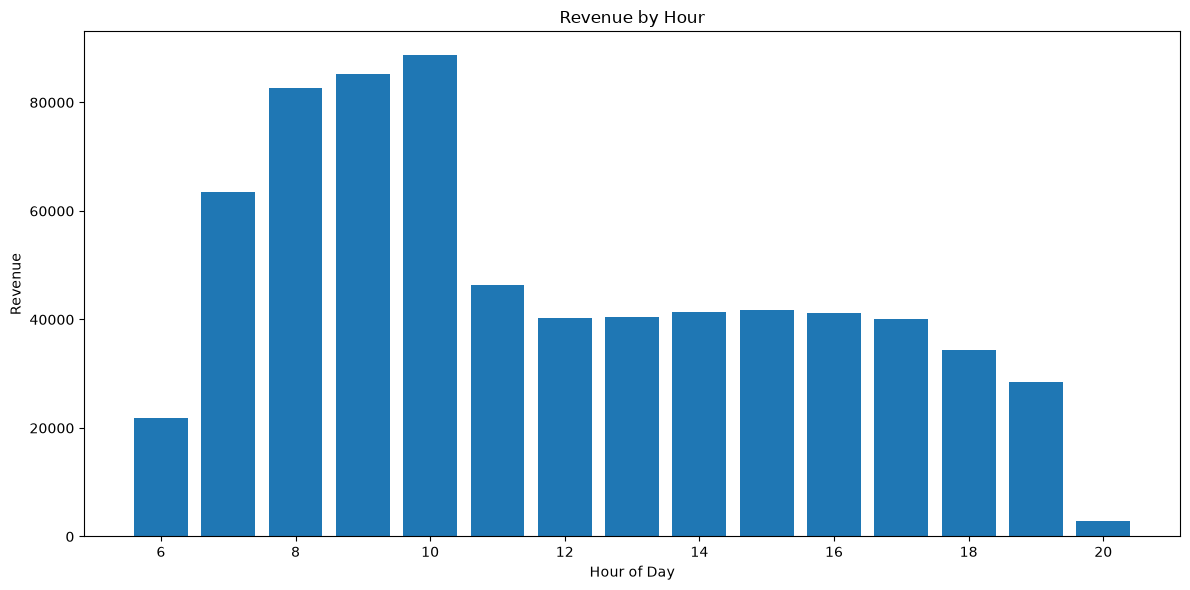

In [ ]:
# Save Revenue by Hour chart

plt.figure(figsize=(12, 6))

plt.bar(
    revenue_by_hour.index,
    revenue_by_hour.values
)

plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.title("Revenue by Hour")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/revenue_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the original dataset
file_path = "../data/Afficionado Coffee Roasters.xlsx"
df = pd.read_excel(file_path)

# Prepare transaction time
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S",
    errors="coerce"
)

# Extract hour
df["hour"] = df["transaction_time"].dt.hour

# Calculate revenue
df["revenue"] = df["transaction_qty"] * df["unit_price"]

# Calculate revenue by hour
revenue_by_hour = (
    df.groupby("hour")["revenue"]
    .sum()
    .sort_index()
)

print("Data restored successfully!")
print("Peak revenue hour:", revenue_by_hour.idxmax())
print("Peak revenue:", revenue_by_hour.max())

Data restored successfully!
Peak revenue hour: 10
Peak revenue: 88673.39


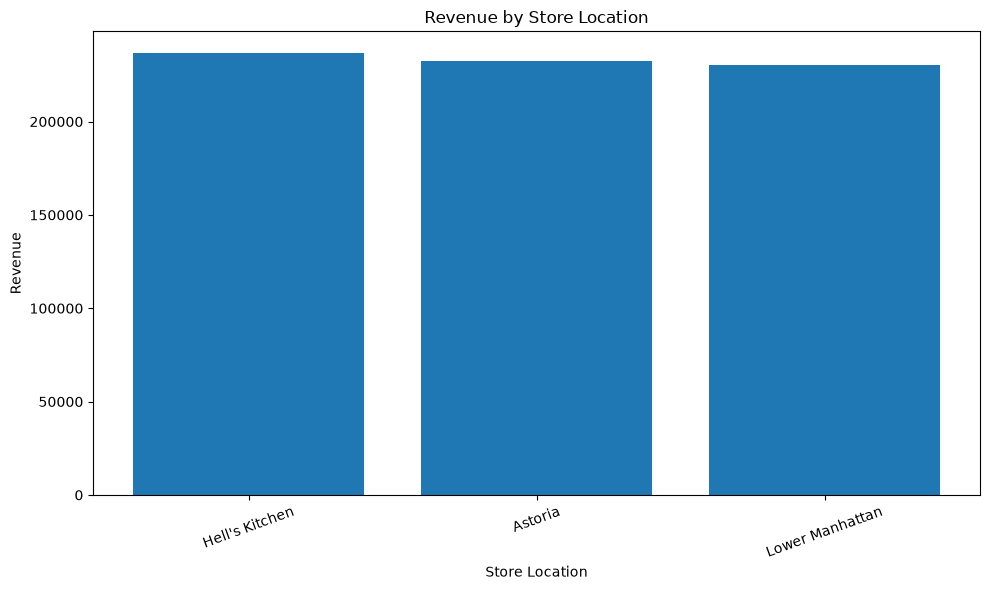

In [8]:
# Save Store Revenue chart

store_revenue = (
    df.groupby("store_location")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    store_revenue.index,
    store_revenue.values
)

plt.xlabel("Store Location")
plt.ylabel("Revenue")
plt.title("Revenue by Store Location")

plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/store_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

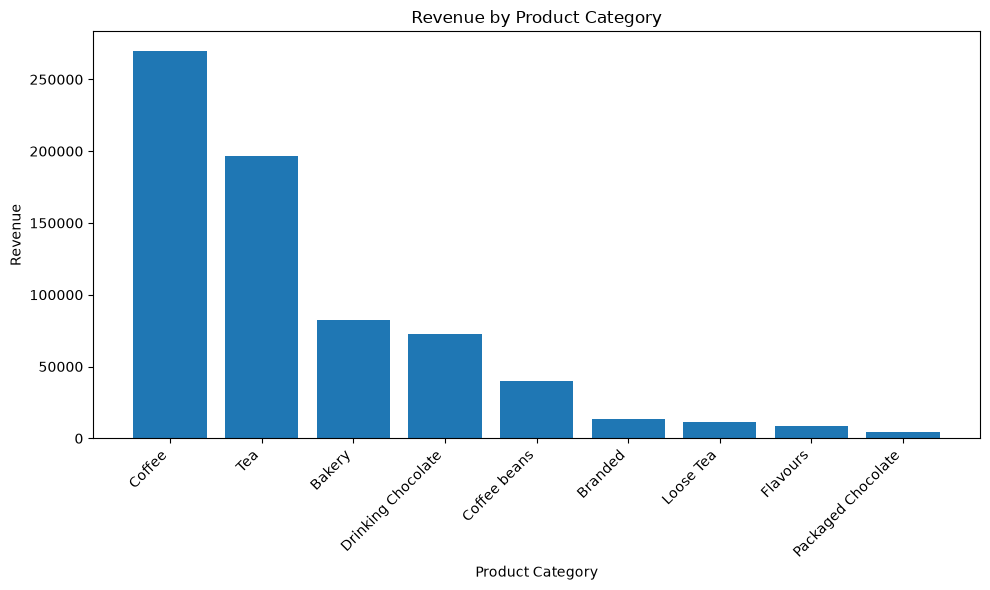

In [9]:
# Save Product Category Revenue chart

category_revenue = (
    df.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    category_revenue.index,
    category_revenue.values
)

plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.title("Revenue by Product Category")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/category_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

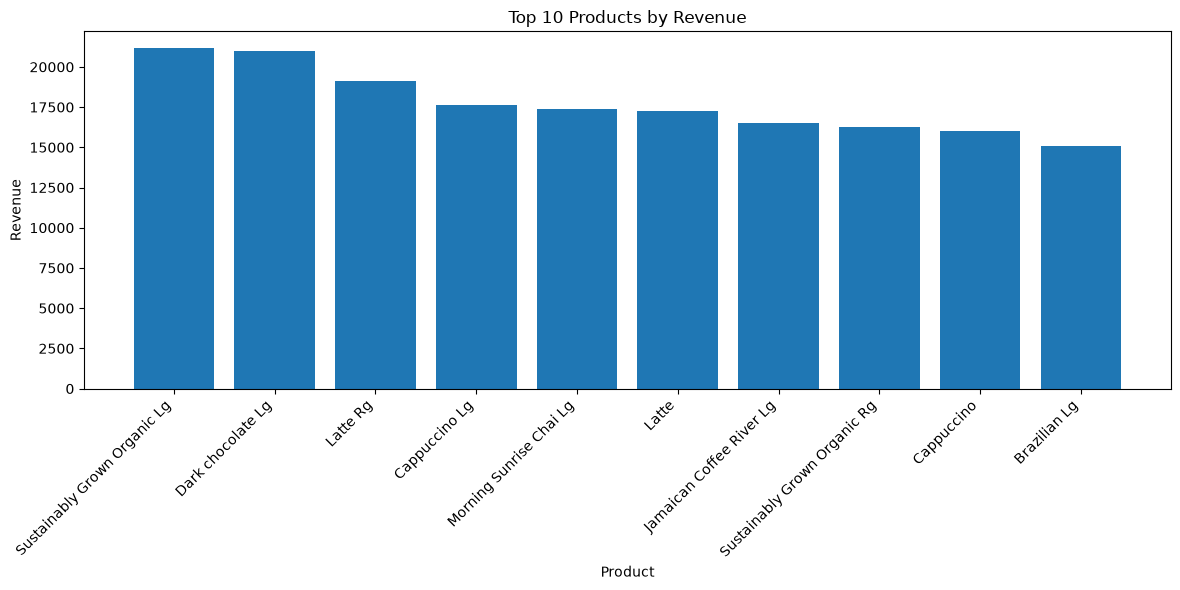

In [10]:
# Save Top 10 Products by Revenue chart

top_products = (
    df.groupby("product_detail")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.bar(
    top_products.index,
    top_products.values
)

plt.xlabel("Product")
plt.ylabel("Revenue")
plt.title("Top 10 Products by Revenue")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Product Type Analysis - Revenue and Quantity

type_revenue = (
    df.groupby("product_type")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

type_quantity = (
    df.groupby("product_type")["transaction_qty"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Type:")
print(type_revenue)

print("\nQuantity Sold by Product Type:")
print(type_quantity)

Revenue by Product Type:
product_type
Barista Espresso         91406.20
Brewed Chai tea          77081.95
Hot chocolate            72416.00
Gourmet brewed coffee    70034.60
Brewed Black tea         47932.00
Brewed herbal tea        47539.50
Premium brewed coffee    38781.15
Organic brewed coffee    37746.50
Scone                    36866.12
Drip coffee              31984.00
Pastry                   25655.99
Brewed Green tea         23852.50
Biscotti                 19793.53
Premium Beans            14583.50
Organic Beans             8509.50
Housewares                7444.00
Gourmet Beans             6798.00
Clothing                  6163.00
Regular syrup             6084.80
Espresso Beans            5560.25
Chai tea                  4301.25
House blend Beans         3294.00
Herbal tea                2729.75
Drinking Chocolate        2728.04
Black tea                 2711.85
Sugar free syrup          2324.00
Organic Chocolate         1679.60
Green tea                 1470.75
Green bean

In [12]:
print("Revenue by Product Type:")
print(type_revenue.to_string())

print("\nQuantity Sold by Product Type:")
print(type_quantity.to_string())

Revenue by Product Type:
product_type
Barista Espresso         91406.20
Brewed Chai tea          77081.95
Hot chocolate            72416.00
Gourmet brewed coffee    70034.60
Brewed Black tea         47932.00
Brewed herbal tea        47539.50
Premium brewed coffee    38781.15
Organic brewed coffee    37746.50
Scone                    36866.12
Drip coffee              31984.00
Pastry                   25655.99
Brewed Green tea         23852.50
Biscotti                 19793.53
Premium Beans            14583.50
Organic Beans             8509.50
Housewares                7444.00
Gourmet Beans             6798.00
Clothing                  6163.00
Regular syrup             6084.80
Espresso Beans            5560.25
Chai tea                  4301.25
House blend Beans         3294.00
Herbal tea                2729.75
Drinking Chocolate        2728.04
Black tea                 2711.85
Sugar free syrup          2324.00
Organic Chocolate         1679.60
Green tea                 1470.75
Green bean

In [13]:
top_10_types_quantity = type_quantity.head(10)

print("Top 10 Product Types by Quantity Sold:")
print(top_10_types_quantity.to_string())

Top 10 Product Types by Quantity Sold:
product_type
Brewed Chai tea          26250
Gourmet brewed coffee    25973
Barista Espresso         24943
Brewed Black tea         17462
Hot chocolate            17457
Brewed herbal tea        17328
Organic brewed coffee    13012
Drip coffee              12891
Premium brewed coffee    12431
Scone                    10465


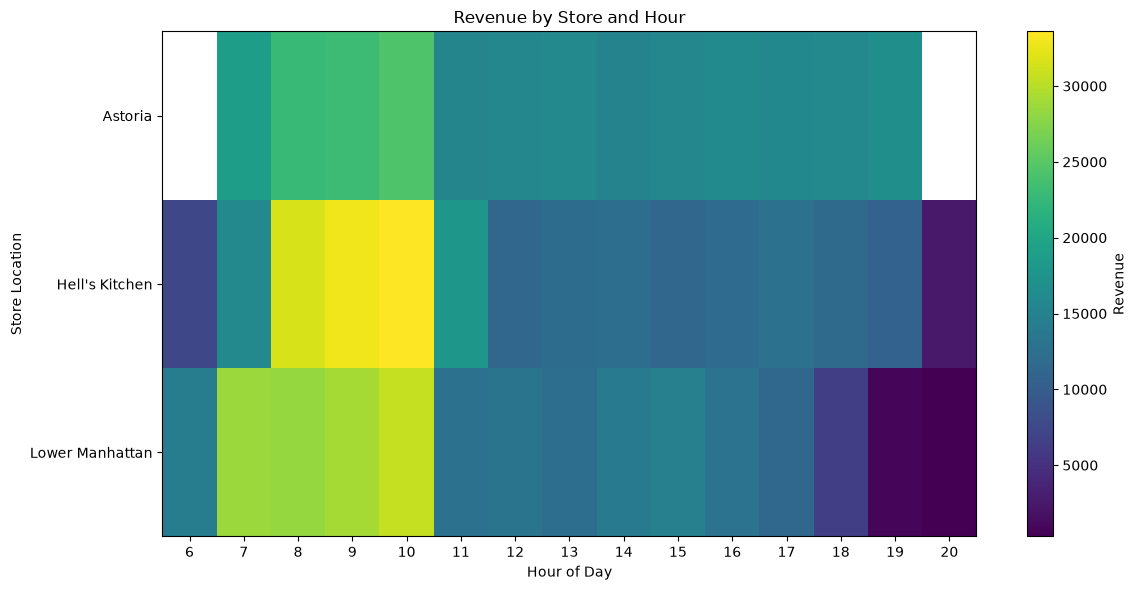

Store-hour heatmap saved successfully!


In [14]:
# Store and Hour Revenue Heatmap

store_hour_revenue = (
    df.groupby(["store_location", "hour"])["revenue"]
    .sum()
    .unstack()
)

plt.figure(figsize=(12, 6))

plt.imshow(store_hour_revenue, aspect="auto", cmap="viridis")

plt.colorbar(label="Revenue")

plt.xticks(
    range(len(store_hour_revenue.columns)),
    store_hour_revenue.columns
)

plt.yticks(
    range(len(store_hour_revenue.index)),
    store_hour_revenue.index
)

plt.xlabel("Hour of Day")
plt.ylabel("Store Location")
plt.title("Revenue by Store and Hour")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/store_hour_revenue_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Store-hour heatmap saved successfully!")